# Avaliação de Modelos - Overcooked
# Análise Comparativa de Modelos Treinados

#### Thaís Ferreira da Silva - 2021092571

**Objetivo:** Carregar e avaliar os modelos salvos durante o treinamento, comparando performance e visualizando comportamentos.

---

## 1. Setup e Imports

In [61]:
# Bibliotecas padrão
import os
import sys
import time
import random
from pathlib import Path
from typing import Dict, List, Tuple
import json

# Bibliotecas científicas
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pandas as pd

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical

# Ambiente
import gymnasium as gym
from overcooked_marl_env import OvercookedMARL

# Configurações
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10
sns.set_style("whitegrid")

# Device detection
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Device: {device}")

Device: cuda


## 2. Definição das Classes

In [62]:
class PettingZooToGymWrapper(gym.Env):
    def __init__(self, pettingzoo_env):
        super().__init__()
        self.env = pettingzoo_env
        
        if len(self.env.possible_agents) != 1:
            raise ValueError(f"Wrapper funciona apenas com 1 agente. Encontrados: {len(self.env.possible_agents)}")
        
        self.agent_id = self.env.possible_agents[0]
        self.action_space = self.env.action_spaces[self.agent_id]
        self.observation_space = self.env.observation_spaces[self.agent_id]
        
    def reset(self, seed=None, options=None):
        observations, infos = self.env.reset(seed=seed, options=options)
        return observations[self.agent_id], infos[self.agent_id]
    
    def step(self, action):
        actions = {self.agent_id: action}
        observations, rewards, terminations, truncations, infos = self.env.step(actions)
        
        obs = observations[self.agent_id]
        reward = rewards[self.agent_id]
        terminated = terminations[self.agent_id]
        truncated = truncations[self.agent_id]
        info = infos[self.agent_id]
        
        return obs, reward, terminated, truncated, info
    
    def render(self):
        return self.env.render()
    
    def close(self):
        self.env.close()

class ActorCritic(nn.Module):
    def __init__(self, observation_space, action_space):
        super().__init__()
        
        h, w, c = observation_space.shape
        n_actions = action_space.n
        
        # Feature extractor (CNN)
        self.cnn = nn.Sequential(
            nn.Conv2d(c, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Flatten(),
        )
        
        # Calcula tamanho da saída
        with torch.no_grad():
            sample = torch.zeros(1, c, h, w)
            n_flatten = self.cnn(sample).shape[1]
        
        # Camadas compartilhadas
        self.shared = nn.Sequential(
            nn.Linear(n_flatten, 128),
            nn.ReLU(),
        )
        
        # Heads
        self.actor = nn.Linear(128, n_actions)
        self.critic = nn.Linear(128, 1)
    
    def forward(self, x):
        x = x.permute(0, 3, 1, 2)
        features = self.shared(self.cnn(x))
        logits = self.actor(features)
        value = self.critic(features)
        return logits, value
    
    def get_action_and_value(self, x, action=None):
        logits, value = self.forward(x)
        probs = Categorical(logits=logits)
        
        if action is None:
            action = probs.sample()
        
        return action, probs.log_prob(action), probs.entropy(), value

## 3. Carregamento e Análise dos Modelos Salvos

In [63]:
def load_model_info(model_path: Path) -> Dict:
    try:
        # CORREÇÃO: Usar weights_only=False para carregar metadados dos modelos
        checkpoint = torch.load(model_path, map_location='cpu', weights_only=False)
        return checkpoint.get('model_info', {})
    except Exception as e:
        print(f"Erro ao carregar {model_path}: {e}")
        return {}

def discover_saved_models(models_dir: str = "models") -> List[Dict]:
    models_path = Path(models_dir)
    
    if not models_path.exists():
        return []
    
    top_10_dir = models_path / "top_10"
    latest_model = models_path / "latest_model.pth"
    
    models_info = []
    
    # Carrega modelos top 10
    if top_10_dir.exists():
        for model_file in top_10_dir.glob("*.pth"):
            info = load_model_info(model_file)
            if info:
                info['path'] = str(model_file)
                info['type'] = 'top_10'
                info['filename'] = model_file.name
                models_info.append(info)
    
    # Carrega modelo mais recente
    if latest_model.exists():
        info = load_model_info(latest_model)
        if info:
            info['path'] = str(latest_model)
            info['type'] = 'latest'
            info['filename'] = latest_model.name
            models_info.append(info)
    
    return models_info

# Descobrir modelos
models_info = discover_saved_models()

if models_info:
    # Cria DataFrame para análise
    df_models = pd.DataFrame(models_info)
    
    # Ordena por reward (decrescente)
    df_models = df_models.sort_values('reward', ascending=False).reset_index(drop=True)
    
    print(f"Modelos encontrados: {len(models_info)}")
    print("\nResumo dos modelos:")
    for i, row in df_models.iterrows():
        print(f"{i+1:2d}. {row['filename']:30} | Update: {row['update']:4d} | Reward: {row['reward']:7.2f} | Episodes: {row['total_episodes']:3d}")
else:
    print("Nenhum modelo encontrado. Execute primeiro o treinamento no notebook 'TP_Overcooked.ipynb'.")
    print("Diretórios verificados:")
    print("- models/top_10/")
    print("- models/latest_model.pth")

Modelos encontrados: 4

Resumo dos modelos:
 1. model_update_0039_reward_121.80.pth | Update:   39 | Reward:  121.80 | Episodes:  19
 2. model_update_0020_reward_98.60.pth | Update:   20 | Reward:   98.60 | Episodes:  10
 3. model_update_0005_reward_77.00.pth | Update:    5 | Reward:   77.00 | Episodes:   2
 4. latest_model.pth               | Update:    3 | Reward:   72.00 | Episodes:   1


## 4. Análise Comparativa de Performance

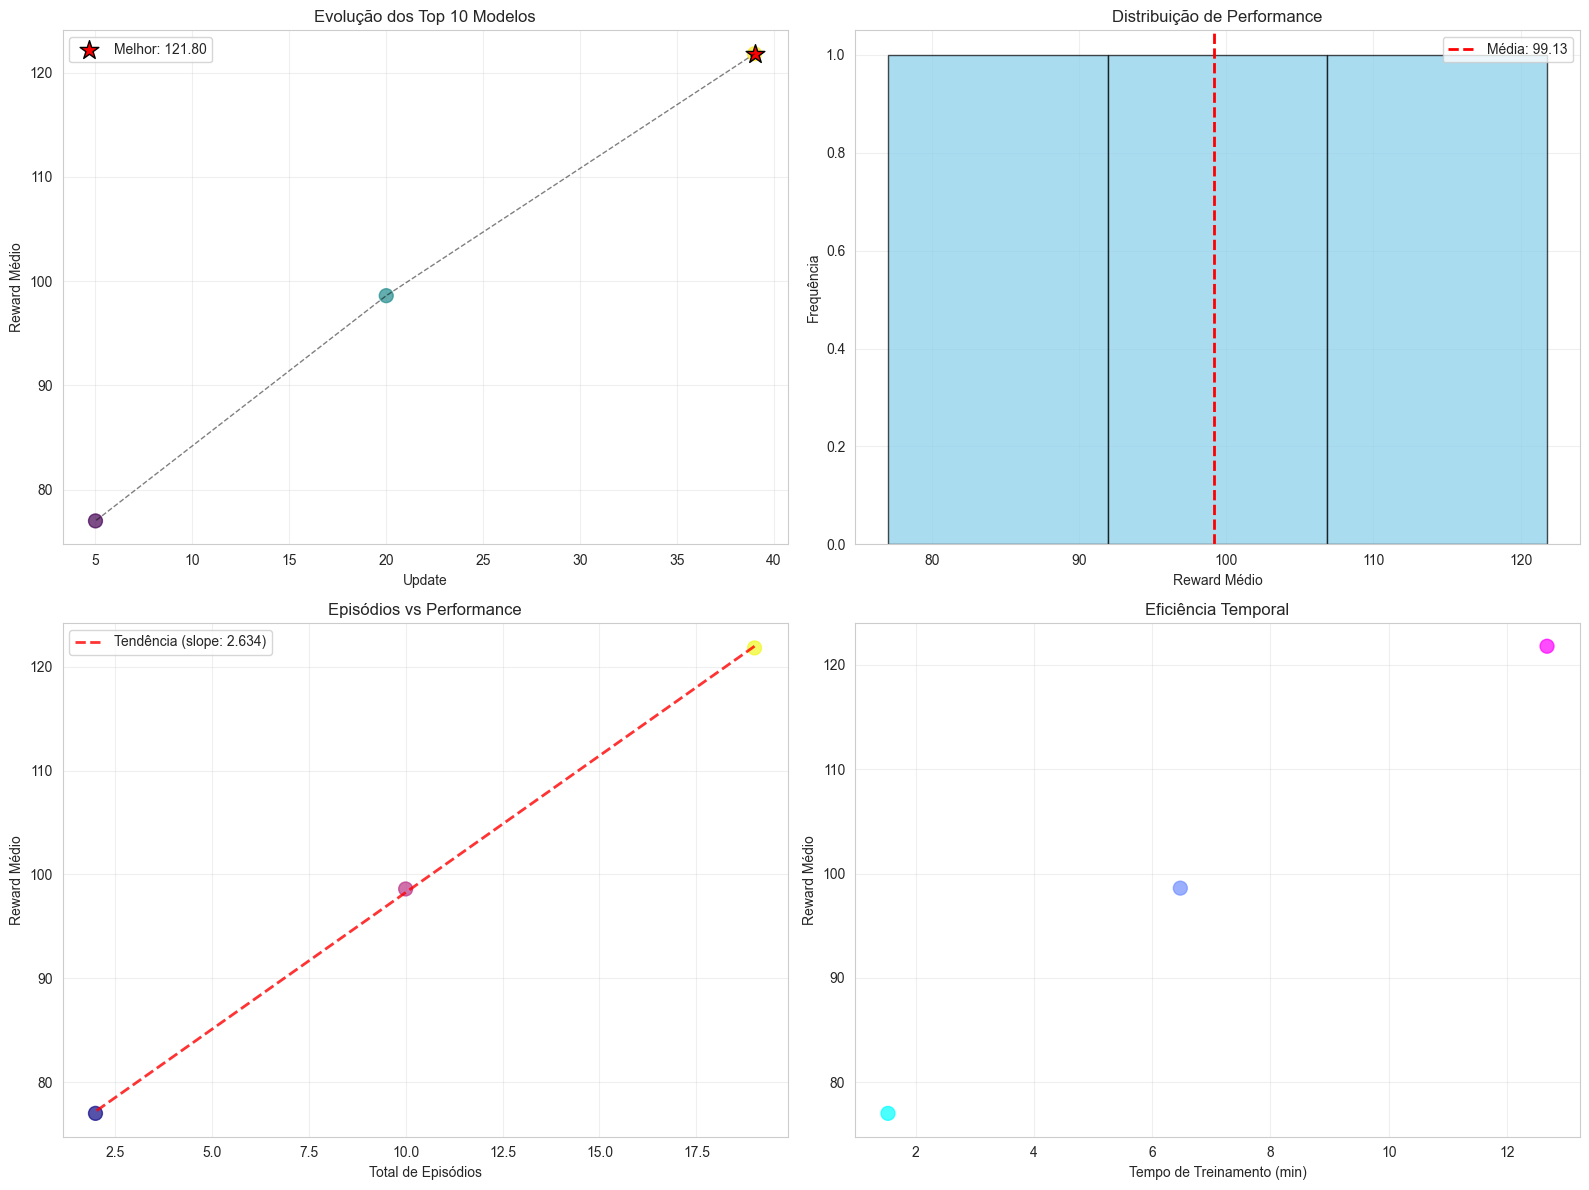


Estatísticas dos modelos:
Melhor reward:     121.80
Pior reward:        77.00
Reward médio:       99.13
Desvio padrão:      22.40
Mediana:            98.60
Amplitude:          44.80


In [64]:
if models_info:
    # Gráfico de evolução dos modelos
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Reward vs Update
    ax1 = axes[0, 0]
    top_10_models = df_models[df_models['type'] == 'top_10']
    
    if len(top_10_models) > 0:
        ax1.scatter(top_10_models['update'], top_10_models['reward'], 
                   c=top_10_models['reward'], cmap='viridis', s=100, alpha=0.7)
        ax1.plot(top_10_models['update'], top_10_models['reward'], 
                'k--', alpha=0.5, linewidth=1)
        
        # Destaca o melhor modelo
        best_model = top_10_models.iloc[0]
        ax1.scatter(best_model['update'], best_model['reward'], 
                   c='red', s=200, marker='*', edgecolor='black', 
                   label=f'Melhor: {best_model["reward"]:.2f}')
    
    ax1.set_xlabel('Update')
    ax1.set_ylabel('Reward Médio')
    ax1.set_title('Evolução dos Top 10 Modelos')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Distribuição de Rewards
    ax2 = axes[0, 1]
    if len(top_10_models) > 0:
        ax2.hist(top_10_models['reward'], bins=min(10, len(top_10_models)), 
                edgecolor='black', alpha=0.7, color='skyblue')
        ax2.axvline(top_10_models['reward'].mean(), color='red', 
                   linestyle='--', linewidth=2, 
                   label=f'Média: {top_10_models["reward"].mean():.2f}')
    ax2.set_xlabel('Reward Médio')
    ax2.set_ylabel('Frequência')
    ax2.set_title('Distribuição de Performance')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Episódios vs Performance
    ax3 = axes[1, 0]
    if len(top_10_models) > 0:
        ax3.scatter(top_10_models['total_episodes'], top_10_models['reward'],
                   c=top_10_models['update'], cmap='plasma', s=100, alpha=0.7)
        
        # Linha de tendência
        z = np.polyfit(top_10_models['total_episodes'], top_10_models['reward'], 1)
        p = np.poly1d(z)
        ax3.plot(top_10_models['total_episodes'], p(top_10_models['total_episodes']),
                "r--", alpha=0.8, linewidth=2, label=f'Tendência (slope: {z[0]:.3f})')
    
    ax3.set_xlabel('Total de Episódios')
    ax3.set_ylabel('Reward Médio')
    ax3.set_title('Episódios vs Performance')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Tempo de treinamento vs Performance
    ax4 = axes[1, 1]
    if len(top_10_models) > 0 and 'training_time' in top_10_models.columns:
        training_times = top_10_models['training_time'] / 60
        ax4.scatter(training_times, top_10_models['reward'],
                   c=top_10_models['update'], cmap='cool', s=100, alpha=0.7)
        ax4.set_xlabel('Tempo de Treinamento (min)')
        ax4.set_ylabel('Reward Médio')
        ax4.set_title('Eficiência Temporal')
        ax4.grid(True, alpha=0.3)
    else:
        ax4.text(0.5, 0.5, 'Dados de tempo\nnão disponíveis', 
                ha='center', va='center', transform=ax4.transAxes, fontsize=12)
        ax4.set_title('Eficiência Temporal')
    
    plt.tight_layout()
    plt.savefig('analise_comparativa_modelos.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # Tabela de estatísticas
    if len(top_10_models) > 0:
        print("\nEstatísticas dos modelos:")
        stats = top_10_models['reward'].describe()
        print(f"Melhor reward:    {stats['max']:7.2f}")
        print(f"Pior reward:      {stats['min']:7.2f}")
        print(f"Reward médio:     {stats['mean']:7.2f}")
        print(f"Desvio padrão:    {stats['std']:7.2f}")
        print(f"Mediana:          {stats['50%']:7.2f}")
        print(f"Amplitude:        {stats['max'] - stats['min']:7.2f}")
else:
    print("Sem modelos para analisar")

## 5. Avaliação Detalhada dos Modelos

In [65]:
def load_and_evaluate_model(model_path: str, env, num_episodes: int = 10, max_steps: int = 300) -> Dict:
    # Carrega checkpoint - CORREÇÃO: weights_only=False
    checkpoint = torch.load(model_path, map_location=device, weights_only=False)
    model_info = checkpoint.get('model_info', {})
    
    # Cria e carrega o modelo
    agent = ActorCritic(env.observation_space, env.action_space).to(device)
    agent.load_state_dict(checkpoint['model_state_dict'])
    agent.eval()
    
    # Avalia performance
    episode_rewards = []
    episode_lengths = []
    episode_info = []
    
    with torch.no_grad():
        for episode in range(num_episodes):
            obs, _ = env.reset()
            episode_reward = 0
            steps = 0
            
            done = False
            while not done and steps < max_steps:
                obs_tensor = torch.FloatTensor(obs).unsqueeze(0).to(device)
                action, _, _, _ = agent.get_action_and_value(obs_tensor)
                
                obs, reward, terminated, truncated, info = env.step(action.cpu().item())
                done = terminated or truncated
                
                episode_reward += reward
                steps += 1
            
            episode_rewards.append(episode_reward)
            episode_lengths.append(steps)
            episode_info.append({'reward': episode_reward, 'length': steps})
    
    # Calcula estatísticas
    results = {
        'model_path': model_path,
        'training_info': model_info,
        'eval_episodes': num_episodes,
        'eval_rewards': episode_rewards,
        'eval_lengths': episode_lengths,
        'mean_reward': np.mean(episode_rewards),
        'std_reward': np.std(episode_rewards),
        'mean_length': np.mean(episode_lengths),
        'std_length': np.std(episode_lengths),
        'success_rate': np.mean([r > -50 for r in episode_rewards]),
    }
    
    return results, agent

# Configura ambiente para avaliação
eval_env = OvercookedMARL(
    render_mode=None,
    map_path="overcooked_marl_env/map/maps/simple_map.txt",
    num_fixed_agents=1,
    verbose=False
)
eval_env = PettingZooToGymWrapper(eval_env)

[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


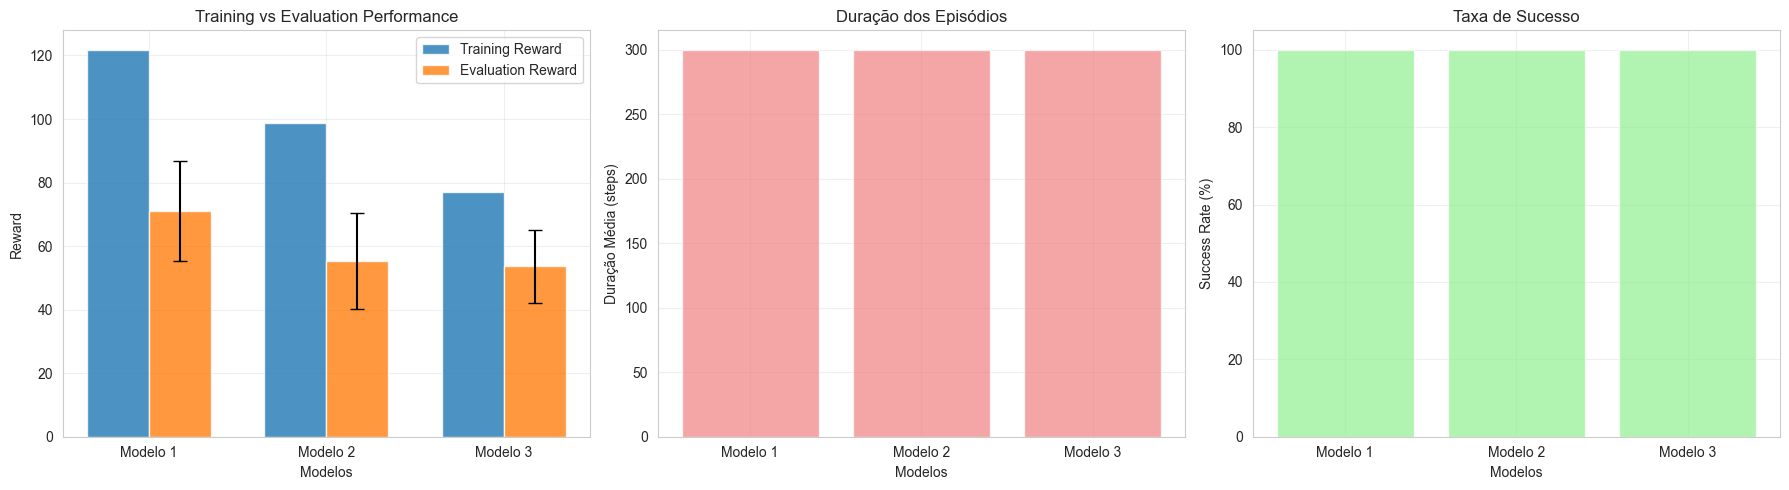

Model       | Train Reward | Eval Reward  | Eval Length | Success Rate
----------------------------------------------------------------------
Modelo  1   |      121.80 |   71.10±15.64 |      300.0 |      100.0%
Modelo  2   |       98.60 |   55.30±15.14 |      300.0 |      100.0%
Modelo  3   |       77.00 |   53.60±11.55 |      300.0 |      100.0%


In [66]:
# Avalia os top 3 modelos
if models_info and len(df_models) > 0:
    num_models_to_evaluate = min(3, len(df_models))
    
    evaluation_results = []
    
    for i in range(num_models_to_evaluate):
        model_row = df_models.iloc[i]
        model_path = model_row['path']
        
        try:
            results, agent = load_and_evaluate_model(model_path, eval_env, num_episodes=20)
            evaluation_results.append(results)
            
        except Exception as e:
            print(f"Erro na avaliação do modelo {i+1}: {e}")
    
    # Gráfico comparativo das avaliações
    if evaluation_results:
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        # Dados para plots
        model_names = [f"Modelo {i+1}" for i in range(len(evaluation_results))]
        training_rewards = [df_models.iloc[i]['reward'] for i in range(len(evaluation_results))]
        eval_means = [r['mean_reward'] for r in evaluation_results]
        eval_stds = [r['std_reward'] for r in evaluation_results]
        eval_lengths = [r['mean_length'] for r in evaluation_results]
        success_rates = [r['success_rate'] for r in evaluation_results]
        
        # 1. Comparação Training vs Evaluation
        x = np.arange(len(model_names))
        width = 0.35
        
        axes[0].bar(x - width/2, training_rewards, width, label='Training Reward', alpha=0.8)
        axes[0].bar(x + width/2, eval_means, width, yerr=eval_stds, 
                   label='Evaluation Reward', alpha=0.8, capsize=5)
        
        axes[0].set_xlabel('Modelos')
        axes[0].set_ylabel('Reward')
        axes[0].set_title('Training vs Evaluation Performance')
        axes[0].set_xticks(x)
        axes[0].set_xticklabels(model_names)
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)
        
        # 2. Episode Length
        axes[1].bar(model_names, eval_lengths, color='lightcoral', alpha=0.7)
        axes[1].set_xlabel('Modelos')
        axes[1].set_ylabel('Duração Média (steps)')
        axes[1].set_title('Duração dos Episódios')
        axes[1].grid(True, alpha=0.3)
        
        # 3. Success Rate
        axes[2].bar(model_names, [s*100 for s in success_rates], color='lightgreen', alpha=0.7)
        axes[2].set_xlabel('Modelos')
        axes[2].set_ylabel('Success Rate (%)')
        axes[2].set_title('Taxa de Sucesso')
        axes[2].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('comparacao_avaliacao_modelos.png', dpi=150, bbox_inches='tight')
        plt.show()
        
        # Tabela resumo
        print("Model       | Train Reward | Eval Reward  | Eval Length | Success Rate")
        print("-" * 70)
        for i, (result, train_r) in enumerate(zip(evaluation_results, training_rewards)):
            print(f"Modelo {i+1:2d}   |     {train_r:7.2f} |   {result['mean_reward']:5.2f}±{result['std_reward']:4.2f} |    {result['mean_length']:7.1f} |      {result['success_rate']:5.1%}")

else:
    print("Nenhum modelo encontrado para avaliação. Execute primeiro o treinamento.")

## 6. Visualização do Comportamento dos Modelos

[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


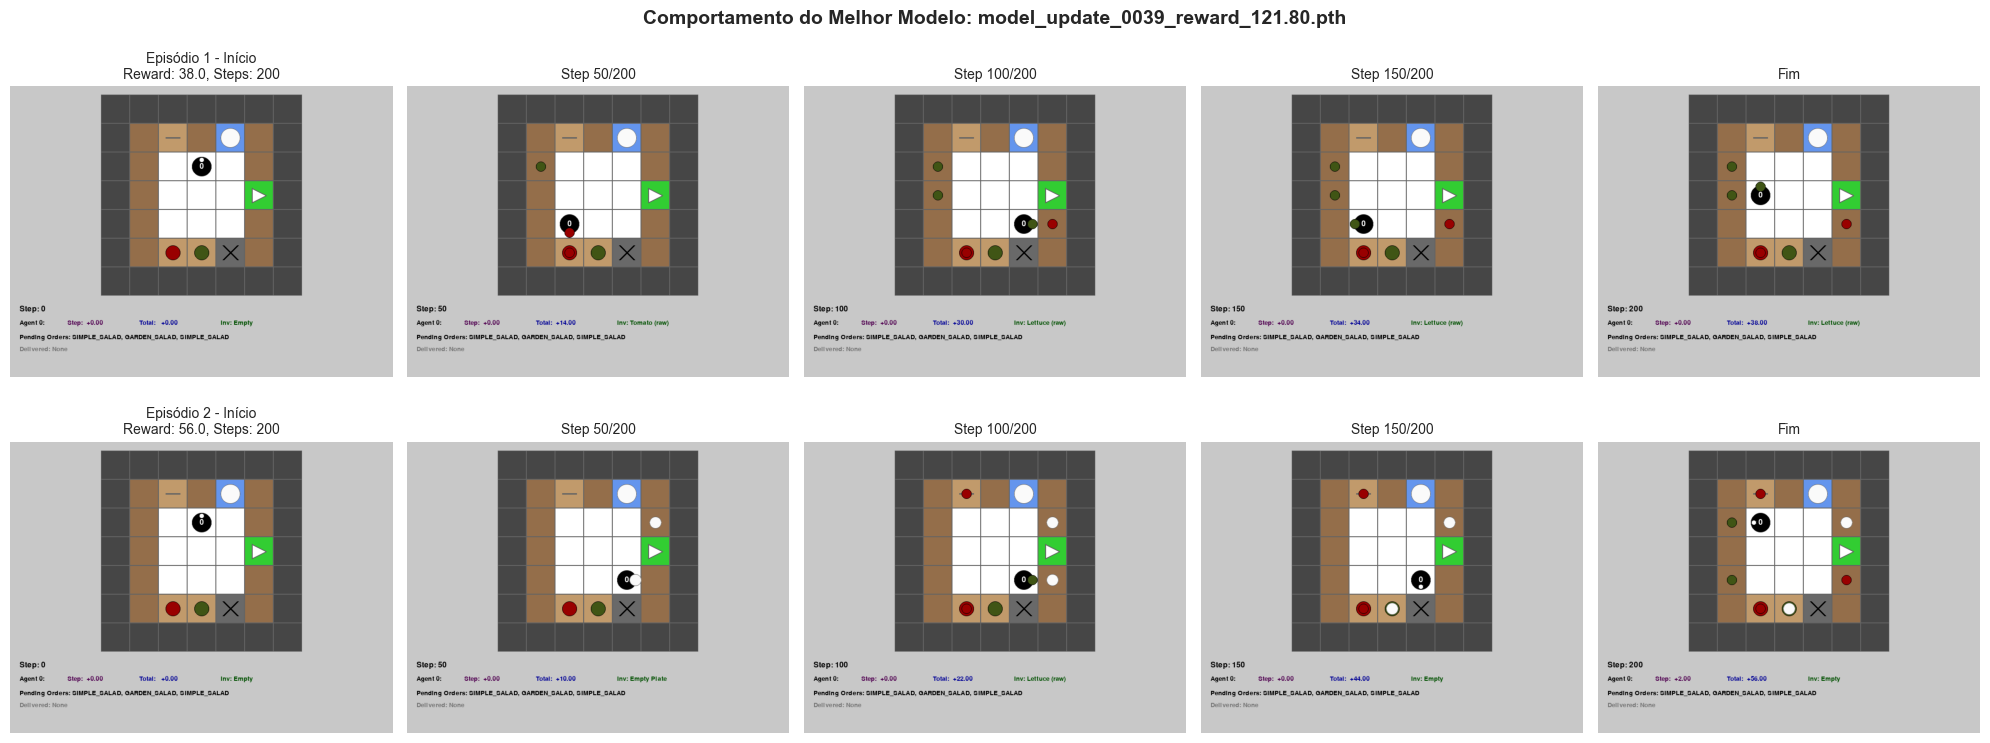

In [67]:
def visualize_model_behavior(model_path: str, num_episodes: int = 2, max_steps: int = 200):
    # Carrega modelo - CORREÇÃO: weights_only=False
    checkpoint = torch.load(model_path, map_location=device, weights_only=False)
    agent = ActorCritic(eval_env.observation_space, eval_env.action_space).to(device)
    agent.load_state_dict(checkpoint['model_state_dict'])
    agent.eval()
    
    # Cria ambiente com renderização
    viz_env = OvercookedMARL(
        render_mode="rgb_array",
        map_path="overcooked_marl_env/map/maps/simple_map.txt",
        num_fixed_agents=1,
        verbose=False
    )
    viz_env = PettingZooToGymWrapper(viz_env)
    
    all_frames = []
    episodes_info = []
    
    with torch.no_grad():
        for episode in range(num_episodes):
            obs, _ = viz_env.reset()
            episode_frames = []
            episode_reward = 0
            steps = 0
            
            # Frame inicial
            frame = viz_env.env.render()
            if frame is not None:
                episode_frames.append(frame)
            
            done = False
            while not done and steps < max_steps:
                obs_tensor = torch.FloatTensor(obs).unsqueeze(0).to(device)
                action, _, _, _ = agent.get_action_and_value(obs_tensor)
                
                obs, reward, terminated, truncated, info = viz_env.step(action.cpu().item())
                done = terminated or truncated
                
                episode_reward += reward
                steps += 1
                
                frame = viz_env.env.render()
                if frame is not None:
                    episode_frames.append(frame)
            
            all_frames.append(episode_frames)
            episodes_info.append({
                'episode': episode + 1,
                'reward': episode_reward,
                'steps': steps
            })
    
    viz_env.close()
    return all_frames, episodes_info

# Visualiza o melhor modelo
if 'evaluation_results' in locals() and evaluation_results:
    best_model_path = df_models.iloc[0]['path']
    best_model_name = df_models.iloc[0]['filename']
    
    try:
        frames, episodes_info = visualize_model_behavior(best_model_path, num_episodes=2)
        
        # Plot dos frames
        num_episodes_viz = len(frames)
        fig, axes = plt.subplots(num_episodes_viz, 5, figsize=(20, 4 * num_episodes_viz))
        
        if num_episodes_viz == 1:
            axes = [axes]
        
        for episode_idx, (episode_frames, info) in enumerate(zip(frames, episodes_info)):
            if len(episode_frames) == 0:
                continue
            
            # 5 frames igualmente espaçados
            indices = np.linspace(0, len(episode_frames) - 1, 5, dtype=int)
            
            for col_idx, frame_idx in enumerate(indices):
                ax = axes[episode_idx][col_idx] if num_episodes_viz > 1 else axes[col_idx]
                ax.imshow(episode_frames[frame_idx])
                ax.axis('off')
                
                if col_idx == 0:
                    ax.set_title(f"Episódio {info['episode']} - Início\n"
                                f"Reward: {info['reward']:.1f}, Steps: {info['steps']}", 
                                fontsize=10)
                elif col_idx == len(indices) - 1:
                    ax.set_title(f"Fim", fontsize=10)
                else:
                    ax.set_title(f"Step {frame_idx}/{len(episode_frames)-1}", fontsize=10)
        
        plt.suptitle(f'Comportamento do Melhor Modelo: {best_model_name}', 
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(f'visualizacao_melhor_modelo.png', dpi=150, bbox_inches='tight')
        plt.show()
        
    except Exception as e:
        print(f"Erro na visualização: {e}")

else:
    print("Execute a avaliação dos modelos primeiro.")

## 7. Relatório Final e Recomendações

In [68]:
if models_info and 'evaluation_results' in locals() and evaluation_results:
    print("=" * 60)
    print("RELATÓRIO FINAL DE AVALIAÇÃO DOS MODELOS")
    print("=" * 60)
    
    # Melhor modelo overall
    best_eval_idx = np.argmax([r['mean_reward'] for r in evaluation_results])
    best_eval_model = evaluation_results[best_eval_idx]
    
    print(f"\nMelhor modelo para produção:")
    print(f"Arquivo: {Path(best_eval_model['model_path']).name}")
    print(f"Performance de avaliação: {best_eval_model['mean_reward']:.2f} ± {best_eval_model['std_reward']:.2f}")
    print(f"Taxa de sucesso: {best_eval_model['success_rate']:.1%}")
    print(f"Duração média: {best_eval_model['mean_length']:.1f} steps")
    
    print(f"\nRecomendações:")
    
    # Analisa overfitting
    training_rewards = [df_models.iloc[i]['reward'] for i in range(len(evaluation_results))]
    eval_rewards = [r['mean_reward'] for r in evaluation_results]
    
    overfitting_scores = [train - eval for train, eval in zip(training_rewards, eval_rewards)]
    avg_overfitting = np.mean(overfitting_scores)
    
    if avg_overfitting > 10:
        print(f"OVERFITTING DETECTADO (diff: {avg_overfitting:.1f})")
        print(f"- Considere mais regularização (entropy coefficient)")
        print(f"- Reduza learning rate")
        print(f"- Adicione mais variação no ambiente")
    else:
        print(f"Generalização adequada (diff: {avg_overfitting:.1f})")
    
    # Analisa estabilidade
    stability = np.mean([r['std_reward'] for r in evaluation_results])
    if stability > 20:
        print(f"ALTA VARIABILIDADE (std: {stability:.1f})")
        print(f"- Modelo inconsistente entre episódios")
        print(f"- Considere mais treinamento ou ajuste de hiperparâmetros")
    else:
        print(f"Performance estável (std: {stability:.1f})")
    
    # Analisa eficiência
    avg_length = np.mean([r['mean_length'] for r in evaluation_results])
    if avg_length > 250:
        print(f"EPISÓDIOS MUITO LONGOS ({avg_length:.0f} steps)")
        print(f"- Agente pode estar preso em comportamentos ineficientes")
    else:
        print(f"Duração de episódios adequada ({avg_length:.0f} steps)")
    
    best_reward = max(eval_rewards)
    


    
    # Salva relatório
    report_data = {
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
        'total_models_found': len(models_info),
        'models_evaluated': len(evaluation_results),
        'best_model': {
            'path': best_eval_model['model_path'],
            'eval_reward': float(best_eval_model['mean_reward']),
            'eval_std': float(best_eval_model['std_reward']),
            'success_rate': float(best_eval_model['success_rate'])
        },
        'overfitting_score': float(avg_overfitting),
        'stability_score': float(stability),
        'evaluation_results': [
            {
                'model_path': r['model_path'],
                'mean_reward': float(r['mean_reward']),
                'std_reward': float(r['std_reward']),
                'success_rate': float(r['success_rate'])
            }
            for r in evaluation_results
        ]
    }
    
    with open('relatorio_avaliacao_modelos.json', 'w') as f:
        json.dump(report_data, f, indent=2)


else:
    print("Execute primeiro o treinamento no notebook 'TP_Overcooked.ipynb' para gerar modelos.")

print("\nAvaliação completa.")

RELATÓRIO FINAL DE AVALIAÇÃO DOS MODELOS

Melhor modelo para produção:
Arquivo: model_update_0039_reward_121.80.pth
Performance de avaliação: 71.10 ± 15.64
Taxa de sucesso: 100.0%
Duração média: 300.0 steps

Recomendações:
OVERFITTING DETECTADO (diff: 39.1)
- Considere mais regularização (entropy coefficient)
- Reduza learning rate
- Adicione mais variação no ambiente
Performance estável (std: 14.1)
EPISÓDIOS MUITO LONGOS (300 steps)
- Agente pode estar preso em comportamentos ineficientes

Avaliação completa.


---

## Instruções de Uso

### Para usar este notebook:

1. **Execute primeiro o notebook de treinamento** (`TP_Overcooked.ipynb`) para gerar modelos
2. **Execute todas as células** deste notebook sequencialmente
3. **Analise os resultados** nos gráficos e relatórios gerados

### Outputs gerados:

- `analise_comparativa_modelos.png` - Análise dos modelos
- `comparacao_avaliacao_modelos.png` - Comparação training vs evaluation
- `visualizacao_melhor_modelo.png` - Comportamento visual do melhor modelo
- `relatorio_avaliacao_modelos.json` - Relatório detalhado em JSON

### Métricas analisadas:

- **Performance**: Reward médio e estabilidade
- **Generalização**: Comparação training vs evaluation
- **Eficiência**: Duração dos episódios
- **Consistência**: Variabilidade entre episódios
- **Comportamento**: Visualização de trajetórias

---